<a href="https://colab.research.google.com/github/mbryan56/Intro-Machine-Learning-Projects/blob/main/Homework_7_Intro_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import time
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configure device (GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Standardized CIFAR-10 preprocessing and data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

batch_size = 64

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model, trainloader, testloader, optimizer, criterion, epochs=30, device=device):
    model.to(device)
    train_losses = []
    train_accs = []
    test_accs = []

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            inputs = inputs.view(inputs.size(0), -1)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)

        # Evaluate on test set
        model.eval()
        test_correct = 0
        test_total = 0
        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                inputs = inputs.view(inputs.size(0), -1)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                test_total += labels.size(0)
                test_correct += predicted.eq(labels).sum().item()

        test_acc = test_correct / test_total
        test_accs.append(test_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")

    training_time = time.time() - start_time
    print(f"Training completed in {training_time:.2f} seconds.\n")
    return model, train_losses, train_accs, test_accs, training_time

Using device: cpu


In [ ]:
criterion = nn.CrossEntropyLoss()

# ==============================================================================
# PROBLEM 1.a: BASELINE MLP (2 Hidden Layers: 512 -> 256)
# ==============================================================================
class BaselineMLP(nn.Module):
    def __init__(self):
        super(BaselineMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

print("--- Training Problem 1.a: Baseline MLP ---")
model_1a = BaselineMLP()
print(f"Problem 1.a Trainable Parameters: {count_parameters(model_1a):,}")
optimizer_1a = optim.Adam(model_1a.parameters(), lr=0.001)

epochs_1a = 30
model_1a, losses_1a, train_acc_1a, test_acc_1a, time_1a = train_and_evaluate(
    model_1a, trainloader, testloader, optimizer_1a, criterion, epochs=epochs_1a
)

# ==============================================================================
# PROBLEM 1.b: EXTENDED DEPTH MLP (+2 Hidden Layers: 512 -> 256 -> 256 -> 128)
# ==============================================================================
class ExtendedMLP(nn.Module):
    def __init__(self):
        super(ExtendedMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(256, 256)
        self.relu3 = nn.ReLU()
        self.fc4 = nn.Linear(256, 128)
        self.relu4 = nn.ReLU()
        self.fc5 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.relu3(self.fc3(x))
        x = self.relu4(self.fc4(x))
        x = self.fc5(x)
        return x

print("--- Training Problem 1.b: Extended Depth MLP ---")
model_1b = ExtendedMLP()
print(f"Problem 1.b Trainable Parameters: {count_parameters(model_1b):,}")
optimizer_1b = optim.Adam(model_1b.parameters(), lr=0.001)

epochs_1b = 30
model_1b, losses_1b, train_acc_1b, test_acc_1b, time_1b = train_and_evaluate(
    model_1b, trainloader, testloader, optimizer_1b, criterion, epochs=epochs_1b
)

--- Training Problem 1.a: Baseline MLP ---
Problem 1.a Trainable Parameters: 1,707,274
Epoch [1/30] | Loss: 1.6577 | Train Acc: 41.04% | Test Acc: 46.22%
Epoch [2/30] | Loss: 1.4644 | Train Acc: 48.29% | Test Acc: 48.85%
Epoch [3/30] | Loss: 1.3640 | Train Acc: 51.72% | Test Acc: 47.18%
Epoch [4/30] | Loss: 1.2868 | Train Acc: 54.34% | Test Acc: 50.42%
Epoch [5/30] | Loss: 1.2149 | Train Acc: 57.02% | Test Acc: 50.79%
Epoch [6/30] | Loss: 1.1461 | Train Acc: 59.48% | Test Acc: 51.57%
Epoch [7/30] | Loss: 1.0899 | Train Acc: 61.25% | Test Acc: 52.40%
Epoch [8/30] | Loss: 1.0223 | Train Acc: 63.38% | Test Acc: 51.68%
Epoch [9/30] | Loss: 0.9676 | Train Acc: 65.29% | Test Acc: 52.47%
Epoch [10/30] | Loss: 0.9126 | Train Acc: 67.56% | Test Acc: 51.93%
Epoch [11/30] | Loss: 0.8629 | Train Acc: 68.93% | Test Acc: 50.45%
Epoch [12/30] | Loss: 0.8119 | Train Acc: 70.95% | Test Acc: 51.97%
Epoch [13/30] | Loss: 0.7700 | Train Acc: 72.24% | Test Acc: 52.22%
Epoch [14/30] | Loss: 0.7184 | Train A

In [ ]:
# ==============================================================================
# PROBLEM 2.a: DEEP MLP (10 Hidden Layers)
# ==============================================================================
class DeepMLP(nn.Module):
    def __init__(self):
        super(DeepMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.input_layer = nn.Linear(3 * 32 * 32, 256)
        self.hidden_layers = nn.ModuleList([nn.Linear(256, 256) for _ in range(10)])
        self.relu = nn.ReLU()
        self.output_layer = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.input_layer(x))
        for layer in self.hidden_layers:
            x = self.relu(layer(x))
        x = self.output_layer(x)
        return x

print("--- Training Problem 2.a: Deep MLP (10 Hidden Layers) ---")
model_2a = DeepMLP()
print(f"Problem 2.a Trainable Parameters: {count_parameters(model_2a):,}")
optimizer_2a = optim.Adam(model_2a.parameters(), lr=0.001)

epochs_2a = 40
model_2a, losses_2a, train_acc_2a, test_acc_2a, time_2a = train_and_evaluate(
    model_2a, trainloader, testloader, optimizer_2a, criterion, epochs=epochs_2a
)

# ==============================================================================
# PROBLEM 2.b: WIDTH & ACTIVATION FUNCTION EXPERIMENTS
# ==============================================================================
# Experiment 1: Increasing Width (2x Neurons: 1024 -> 512)
class WideMLP(nn.Module):
    def __init__(self):
        super(WideMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 1024)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(1024, 512)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(512, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

# Experiment 2: Sigmoid Activation
class SigmoidMLP(nn.Module):
    def __init__(self):
        super(SigmoidMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.sigmoid1 = nn.Sigmoid()
        self.fc2 = nn.Linear(512, 256)
        self.sigmoid2 = nn.Sigmoid()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.sigmoid1(self.fc1(x))
        x = self.sigmoid2(self.fc2(x))
        x = self.fc3(x)
        return x

# Experiment 3: Tanh Activation
class TanhMLP(nn.Module):
    def __init__(self):
        super(TanhMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.tanh1 = nn.Tanh()
        self.fc2 = nn.Linear(512, 256)
        self.tanh2 = nn.Tanh()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.tanh1(self.fc1(x))
        x = self.tanh2(self.fc2(x))
        x = self.fc3(x)
        return x

epochs_2b = 30

print("--- Training Problem 2.b (Exp 1): Wide MLP (2x Neurons) ---")
model_wide = WideMLP()
print(f"Wide MLP Parameters: {count_parameters(model_wide):,}")
optimizer_wide = optim.Adam(model_wide.parameters(), lr=0.001)
model_wide, losses_wide, train_acc_wide, test_acc_wide, time_wide = train_and_evaluate(
    model_wide, trainloader, testloader, optimizer_wide, criterion, epochs=epochs_2b
)

print("--- Training Problem 2.b (Exp 2): Sigmoid MLP ---")
model_sig = SigmoidMLP()
print(f"Sigmoid MLP Parameters: {count_parameters(model_sig):,}")
optimizer_sig = optim.Adam(model_sig.parameters(), lr=0.001)
model_sig, losses_sig, train_acc_sig, test_acc_sig, time_sig = train_and_evaluate(
    model_sig, trainloader, testloader, optimizer_sig, criterion, epochs=epochs_2b
)

print("--- Training Problem 2.b (Exp 3): Tanh MLP ---")
model_tanh = TanhMLP()
print(f"Tanh MLP Parameters: {count_parameters(model_tanh):,}")
optimizer_tanh = optim.Adam(model_tanh.parameters(), lr=0.001)
model_tanh, losses_tanh, train_acc_tanh, test_acc_tanh, time_tanh = train_and_evaluate(
    model_tanh, trainloader, testloader, optimizer_tanh, criterion, epochs=epochs_2b
)

--- Training Problem 2.a: Deep MLP (10 Hidden Layers) ---
Problem 2.a Trainable Parameters: 1,447,178
Epoch [1/40] | Loss: 2.0039 | Train Acc: 19.61% | Test Acc: 23.63%
Epoch [2/40] | Loss: 1.8208 | Train Acc: 29.71% | Test Acc: 34.62%
Epoch [3/40] | Loss: 1.6573 | Train Acc: 38.49% | Test Acc: 40.83%
Epoch [4/40] | Loss: 1.5514 | Train Acc: 43.25% | Test Acc: 44.00%
Epoch [5/40] | Loss: 1.4658 | Train Acc: 46.72% | Test Acc: 46.62%
Epoch [6/40] | Loss: 1.3926 | Train Acc: 49.84% | Test Acc: 46.39%
Epoch [7/40] | Loss: 1.3326 | Train Acc: 52.28% | Test Acc: 47.27%
Epoch [8/40] | Loss: 1.2682 | Train Acc: 54.39% | Test Acc: 50.36%
Epoch [9/40] | Loss: 1.2147 | Train Acc: 56.24% | Test Acc: 49.64%
Epoch [10/40] | Loss: 1.1684 | Train Acc: 58.14% | Test Acc: 49.92%
Epoch [11/40] | Loss: 1.1440 | Train Acc: 59.48% | Test Acc: 50.07%
Epoch [12/40] | Loss: 1.0891 | Train Acc: 60.96% | Test Acc: 50.31%
Epoch [13/40] | Loss: 1.0494 | Train Acc: 62.55% | Test Acc: 51.36%
Epoch [14/40] | Loss: 1

                             HOMEWORK 7 COMPLETE EXPERIMENTAL SUMMARY                                    
Experiment               | Epochs | Parameters  | Time (s)  | Train Loss | Train Acc  | Eval Acc  
---------------------------------------------------------------------------------------------------------
1.a Baseline (ReLU)      | 30     | 1,707,274   | 860.31    | 0.3787     | 86.41    % | 52.08    %
1.b Extended (+2 Layers) | 30     | 1,804,682   | 931.25    | 0.3507     | 87.83    % | 53.09    %
2.a Deep (10 Layers)     | 40     | 1,447,178   | 1477.36   | 0.4363     | 85.49    % | 50.43    %
2.b Wide (2x Neurons)    | 30     | 3,676,682   | 1477.62   | 0.4208     | 85.20    % | 52.21    %
2.b Sigmoid Activation   | 30     | 1,707,274   | 1035.84   | 0.6236     | 78.52    % | 49.04    %
2.b Tanh Activation      | 30     | 1,707,274   | 841.83    | 1.1278     | 60.62    % | 46.21    %

--- MODEL ARCHITECTURES SUMMARY ---

[1.a Baseline]
BaselineMLP(
  (flatten): Flatten(start_di

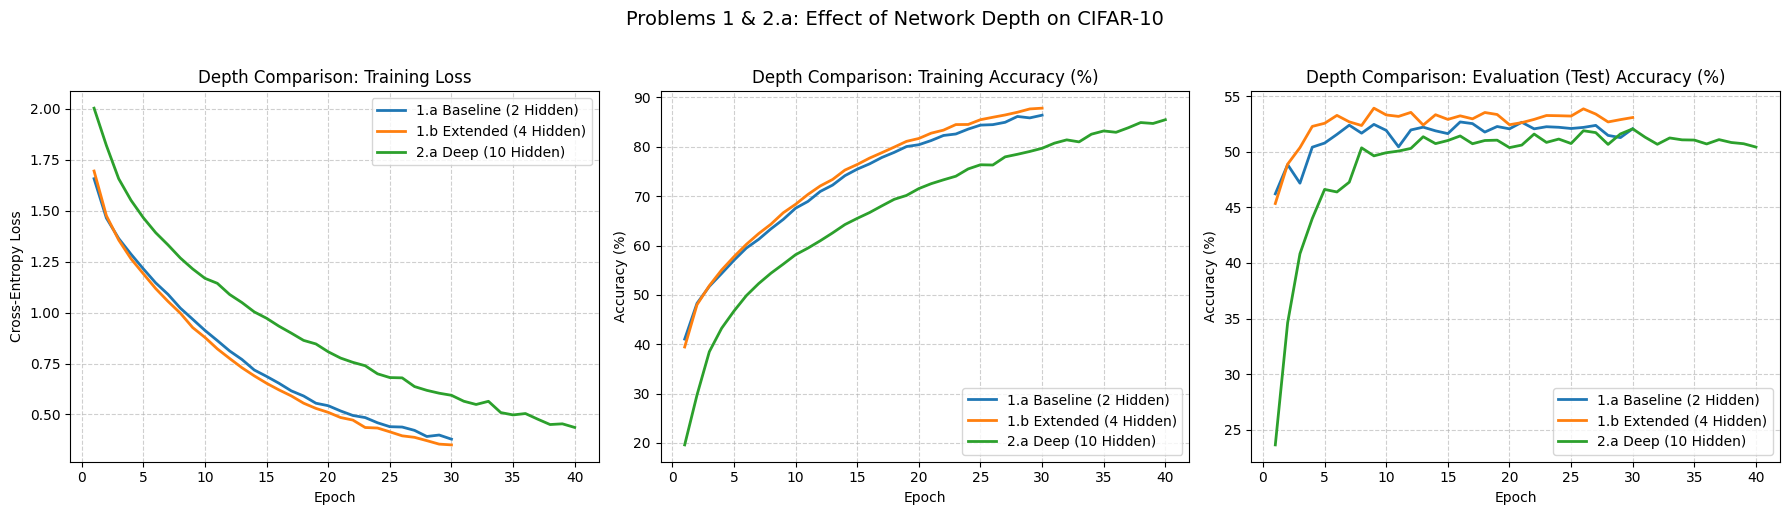

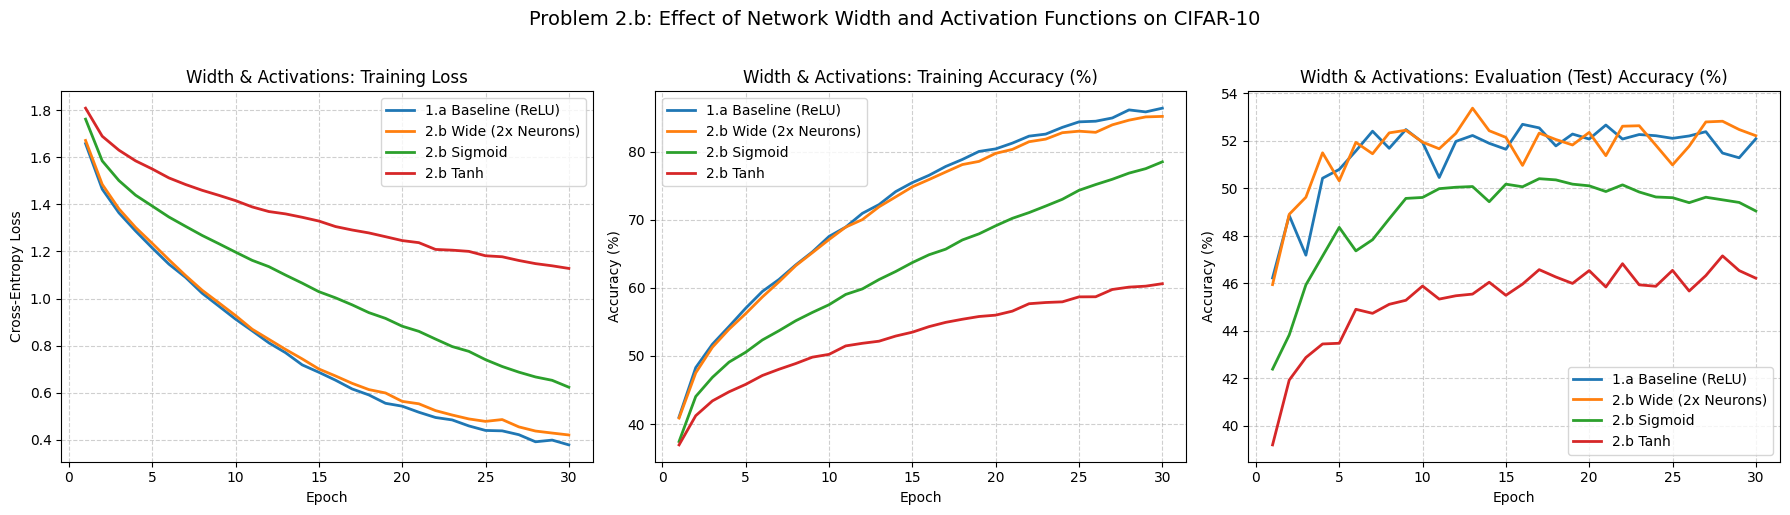

In [ ]:
# ==============================================================================
# 1. COMPLETE SUMMARY COMPARISON TABLE
# ==============================================================================
print("=========================================================================================================")
print("                             HOMEWORK 7 COMPLETE EXPERIMENTAL SUMMARY                                    ")
print("=========================================================================================================")
header = f"{'Experiment':<24} | {'Epochs':<6} | {'Parameters':<11} | {'Time (s)':<9} | {'Train Loss':<10} | {'Train Acc':<10} | {'Eval Acc':<10}"
print(header)
print("-" * 105)

rows = [
    ("1.a Baseline (ReLU)", epochs_1a, count_parameters(model_1a), time_1a, losses_1a[-1], train_acc_1a[-1]*100, test_acc_1a[-1]*100),
    ("1.b Extended (+2 Layers)", epochs_1b, count_parameters(model_1b), time_1b, losses_1b[-1], train_acc_1b[-1]*100, test_acc_1b[-1]*100),
    ("2.a Deep (10 Layers)", epochs_2a, count_parameters(model_2a), time_2a, losses_2a[-1], train_acc_2a[-1]*100, test_acc_2a[-1]*100),
    ("2.b Wide (2x Neurons)", epochs_2b, count_parameters(model_wide), time_wide, losses_wide[-1], train_acc_wide[-1]*100, test_acc_wide[-1]*100),
    ("2.b Sigmoid Activation", epochs_2b, count_parameters(model_sig), time_sig, losses_sig[-1], train_acc_sig[-1]*100, test_acc_sig[-1]*100),
    ("2.b Tanh Activation", epochs_2b, count_parameters(model_tanh), time_tanh, losses_tanh[-1], train_acc_tanh[-1]*100, test_acc_tanh[-1]*100),
]

for name, ep, params, t, loss, tr_acc, te_acc in rows:
    print(f"{name:<24} | {ep:<6} | {params:<11,d} | {t:<9.2f} | {loss:<10.4f} | {tr_acc:<9.2f}% | {te_acc:<9.2f}%")
print("=" * 105)

# ==============================================================================
# 2. MODEL ARCHITECTURES REFERENCE
# ==============================================================================
print("\n--- MODEL ARCHITECTURES SUMMARY ---")
for title, m in [("1.a Baseline", model_1a), ("1.b Extended Depth", model_1b), ("2.a Deep (10-Layer)", model_2a),
                 ("2.b Wide", model_wide), ("2.b Sigmoid", model_sig), ("2.b Tanh", model_tanh)]:
    print(f"\n[{title}]")
    print(m)

# ==============================================================================
# 3. PLOTS: IMPACT OF NETWORK DEPTH (1.a vs 1.b vs 2.a)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(range(1, epochs_1a + 1), losses_1a, label='1.a Baseline (2 Hidden)', linewidth=2)
axes[0].plot(range(1, epochs_1b + 1), losses_1b, label='1.b Extended (4 Hidden)', linewidth=2)
axes[0].plot(range(1, epochs_2a + 1), losses_2a, label='2.a Deep (10 Hidden)', linewidth=2)
axes[0].set_title('Depth Comparison: Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(range(1, epochs_1a + 1), [a*100 for a in train_acc_1a], label='1.a Baseline (2 Hidden)', linewidth=2)
axes[1].plot(range(1, epochs_1b + 1), [a*100 for a in train_acc_1b], label='1.b Extended (4 Hidden)', linewidth=2)
axes[1].plot(range(1, epochs_2a + 1), [a*100 for a in train_acc_2a], label='2.a Deep (10 Hidden)', linewidth=2)
axes[1].set_title('Depth Comparison: Training Accuracy (%)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].plot(range(1, epochs_1a + 1), [a*100 for a in test_acc_1a], label='1.a Baseline (2 Hidden)', linewidth=2)
axes[2].plot(range(1, epochs_1b + 1), [a*100 for a in test_acc_1b], label='1.b Extended (4 Hidden)', linewidth=2)
axes[2].plot(range(1, epochs_2a + 1), [a*100 for a in test_acc_2a], label='2.a Deep (10 Hidden)', linewidth=2)
axes[2].set_title('Depth Comparison: Evaluation (Test) Accuracy (%)')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Problems 1 & 2.a: Effect of Network Depth on CIFAR-10', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. PLOTS: IMPACT OF WIDTH & ACTIVATIONS (1.a vs 2.b)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(range(1, epochs_1a + 1), losses_1a, label='1.a Baseline (ReLU)', linewidth=2)
axes[0].plot(range(1, epochs_2b + 1), losses_wide, label='2.b Wide (2x Neurons)', linewidth=2)
axes[0].plot(range(1, epochs_2b + 1), losses_sig, label='2.b Sigmoid', linewidth=2)
axes[0].plot(range(1, epochs_2b + 1), losses_tanh, label='2.b Tanh', linewidth=2)
axes[0].set_title('Width & Activations: Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(range(1, epochs_1a + 1), [a*100 for a in train_acc_1a], label='1.a Baseline (ReLU)', linewidth=2)
axes[1].plot(range(1, epochs_2b + 1), [a*100 for a in train_acc_wide], label='2.b Wide (2x Neurons)', linewidth=2)
axes[1].plot(range(1, epochs_2b + 1), [a*100 for a in train_acc_sig], label='2.b Sigmoid', linewidth=2)
axes[1].plot(range(1, epochs_2b + 1), [a*100 for a in train_acc_tanh], label='2.b Tanh', linewidth=2)
axes[1].set_title('Width & Activations: Training Accuracy (%)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].plot(range(1, epochs_1a + 1), [a*100 for a in test_acc_1a], label='1.a Baseline (ReLU)', linewidth=2)
axes[2].plot(range(1, epochs_2b + 1), [a*100 for a in test_acc_wide], label='2.b Wide (2x Neurons)', linewidth=2)
axes[2].plot(range(1, epochs_2b + 1), [a*100 for a in test_acc_sig], label='2.b Sigmoid', linewidth=2)
axes[2].plot(range(1, epochs_2b + 1), [a*100 for a in test_acc_tanh], label='2.b Tanh', linewidth=2)
axes[2].set_title('Width & Activations: Evaluation (Test) Accuracy (%)')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Problem 2.b: Effect of Network Width and Activation Functions on CIFAR-10', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()